[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sampriti-sr/MLP_Course/blob/kshitij-variant/docs/toolkit/pandas-grouping.ipynb)

# pandas: Grouping, Merging and Reshaping

<div class="admonition info">
<p class="admonition-title">What you will be able to do after this page</p>
<ul>
<li>Summarise by group with named aggregation, and use transform for row-aligned results.</li>
<li>Spot and fix the small-sample trap in group averages.</li>
<li>Merge safely using validate and indicator, and recognise the row-multiplying join.</li>
<li>Reshape with pivot_table and explode, and summarise over time with resample.</li>
</ul>
</div>

**Prerequisites:** <a href="../pandas-cleaning/">pandas: Cleaning and Types</a>. **Dataset:** MovieLens and Online Retail II. **Time:** about 45 minutes.

In [1]:
try:
    import mlp_data
except ImportError:  # e.g. a fresh Colab runtime
    %pip install -q "mlp-course @ git+https://github.com/sampriti-sr/MLP_Course@kshitij-variant"
    import mlp_data

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mlp_data import load_retail, retail, style

style.apply()
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 14)
pd.set_option("display.float_format", "{:,.2f}".format)

## The situation

Real questions are rarely about single rows. *Which movies are best rated? How much does each customer spend? What is revenue by country and quarter?* They need two skills: **summarising by group** (`groupby`) and **combining tables** (`merge`, `concat`). Both are easy to get subtly wrong without an error message, so this page is as much about the traps as the syntax.

Two real datasets: MovieLens ratings (100,836 ratings of 9,742 movies) for grouping and joining, and the retail transactions for per-customer and time-based summaries.

In [2]:
from mlp_data import load_movielens
ml = load_movielens()
ratings, movies, tags = ml.ratings, ml.movies, ml.tags
print({"ratings": ratings.shape, "movies": movies.shape, "tags": tags.shape})
ratings.head(3)

{'ratings': (100836, 4), 'movies': (9742, 3), 'tags': (3683, 4)}


,userId,movieId,rating,timestamp
0,1,1,4.00,964982703
1,1,3,4.00,964981247
2,1,6,4.00,964982224


## 1. Split, apply, combine

`groupby` splits the table into groups, applies a function to each, and combines the results. The cleanest way to compute several summaries at once is **named aggregation**: `new_name=("column", "function")`.

In [3]:
per_movie = ratings.groupby("movieId").agg(n_ratings=("rating", "size"), mean_rating=("rating", "mean"))
per_movie = per_movie.join(movies.set_index("movieId")["title"])
per_movie.sort_values("mean_rating", ascending=False).head(5)

,n_ratings,mean_rating,title
movieId,,,
88448,1,5.00,Paper Birds (Pájaros de papel) (2010)
100556,1,5.00,"Act of Killing, The (2012)"
143031,1,5.00,Jump In! (2007)
143511,1,5.00,Human (2015)
143559,1,5.00,L.A. Slasher (2015)


The "best" movies by average rating are obscure titles with a perfect 5.0. Look at the `n_ratings` column: each has a single rating. That is the **small-sample trap**: an average of one number is not an average of opinion. How widespread is it?

In [4]:
few = per_movie["n_ratings"] <= 3
perfect = per_movie["mean_rating"] == 5
print(f"movies with 3 or fewer ratings: {few.mean():.0%} of all movies")
print(f"movies with a perfect 5.0 average: {perfect.sum()}, of which {(perfect & few).sum()} have 3 or fewer ratings")
assert (perfect & few).sum() == perfect.sum()        # every perfect average rests on three ratings or fewer

movies with 3 or fewer ratings: 57% of all movies
movies with a perfect 5.0 average: 296, of which 296 have 3 or fewer ratings


**Every one** of the perfect-5.0 movies rests on three ratings or fewer, and more than half of all movies are in that position. Two honest fixes: require a **minimum count**, or **shrink** small samples towards the overall average (a weighted rating: with few ratings you lean on the prior, with many you trust the data).

In [5]:
global_mean = ratings["rating"].mean()
m = 10                                                      # how many ratings we want before trusting a movie's own average
per_movie["shrunk"] = (per_movie["n_ratings"] * per_movie["mean_rating"] + m * global_mean) / (per_movie["n_ratings"] + m)

with_min = per_movie[per_movie["n_ratings"] >= 100].sort_values("mean_rating", ascending=False).head(5)
shrunk = per_movie.sort_values("shrunk", ascending=False).head(5)
print("minimum 100 ratings:"); print(with_min[["n_ratings", "mean_rating", "title"]].to_string())
print("\nshrunk towards the global mean (no minimum needed):"); print(shrunk[["n_ratings", "shrunk", "title"]].to_string())

minimum 100 ratings:
         n_ratings  mean_rating                             title
movieId                                                          
318            317         4.43  Shawshank Redemption, The (1994)
858            192         4.29             Godfather, The (1972)
2959           218         4.27                 Fight Club (1999)
1221           129         4.26    Godfather: Part II, The (1974)
48516          107         4.25              Departed, The (2006)

shrunk towards the global mean (no minimum needed):
         n_ratings  shrunk                             title
movieId                                                     
318            317    4.40  Shawshank Redemption, The (1994)
858            192    4.25             Godfather, The (1972)
2959           218    4.24                 Fight Club (1999)
1221           129    4.21    Godfather: Part II, The (1974)
50             204    4.20        Usual Suspects, The (1995)


Both fixes surface well-known, well-rated films with substantial audiences instead of one-rating curiosities. The shrunk score needs no arbitrary cutoff, and `m` expresses how sceptical you are. (This is the same idea as the regularisation we met in the modelling pages.)

## 2. `agg` versus `transform`

`agg` returns **one row per group**. `transform` returns a result **aligned with the original rows**, which is what you want when the group summary is an input to a row-level calculation, like "this order's share of the customer's total spend". Now the retail data:

In [6]:
from mlp_data import retail
cleaned = retail.clean_retail(load_retail())
sales = cleaned.sales

customer_total = sales.groupby("customer_id")["revenue"].agg(["size", "sum"])                  # agg: one row per customer
sales["share_of_customer_spend"] = sales["revenue"] / sales.groupby("customer_id")["revenue"].transform("sum")   # transform: one value per sales line
print("agg shape:", customer_total.shape, "| transform kept the", len(sales), "rows")
assert np.allclose(sales.groupby("customer_id")["share_of_customer_spend"].sum(), 1.0)       # each customer's shares add to 1
sales[["customer_id", "stock_code", "revenue", "share_of_customer_spend"]].head(4)

agg shape: (5850, 2) | transform kept the 787223 rows


,customer_id,stock_code,revenue,share_of_customer_spend
0,13085,85048,83.40,0.03
1,13085,79323P,81.00,0.03
2,13085,79323W,81.00,0.03
3,13085,22041,100.80,0.04


In [7]:
# per-customer summary with named aggregation, then a within-group ranking
customers = sales.groupby("customer_id").agg(orders=("invoice", "nunique"), spend=("revenue", "sum"), first_order=("invoice_date", "min"), last_order=("invoice_date", "max"))
customers["active_days"] = (customers["last_order"] - customers["first_order"]).dt.days
customers["spend_rank"] = customers["spend"].rank(ascending=False, method="first").astype(int)
customers.sort_values("spend_rank").head(5)[["orders", "spend", "active_days", "spend_rank"]]

,orders,spend,active_days,spend_rank
customer_id,,,,
18102,145,"580,987.04",738,1
14646,145,"526,751.52",735,2
14156,143,"302,361.47",728,3
14911,371,"268,042.13",737,4
17450,50,"238,619.17",429,5


## 3. Two keys at once: `pivot_table`

Group by two things and lay one across the columns. Revenue by country and quarter, for the largest markets:

In [8]:
by_quarter = sales.assign(quarter=sales["invoice_date"].dt.to_period("Q"))
table = by_quarter.pivot_table(index="country", columns="quarter", values="revenue", aggfunc="sum", fill_value=0)
top_markets = table.sum(axis=1).nlargest(5).index
(table.loc[top_markets] / 1000).round(0).astype(int).rename_axis("revenue, £ thousand")

quarter,2009Q4,2010Q1,2010Q2,2010Q3,2010Q4,2011Q1,2011Q2,2011Q3,2011Q4
"revenue, £ thousand",,,,,,,,,
United Kingdom,609,1393,1517,1669,2339,1183,1433,1770,2067
EIRE,17,100,61,88,72,50,42,93,59
Netherlands,15,71,53,75,61,72,59,67,78
Germany,9,35,44,43,60,37,47,49,60
France,6,23,29,36,40,38,34,44,59


`pivot_table` is `groupby` plus a reshape, with `fill_value` for empty cells. The United Kingdom dwarfs everything else, which is the first thing the table is good for telling you.

## 4. Combining tables: `merge`

`merge` is a database join. The key choices are **which columns** to match (`on`), **which rows to keep** (`how`: `inner`, `left`, `right`, `outer`), and, most importantly, **how many rows to expect**. Make pandas check your expectation with `validate`, and look at the unmatched rows with `indicator`.

In [9]:
joined = ratings.merge(movies, on="movieId", how="left", validate="many_to_one", indicator=True)
print(joined["_merge"].value_counts().to_dict(), "| rows:", len(joined), "(same as ratings:", len(ratings), ")")
joined.drop(columns="_merge").head(3)

{'both': 100836, 'left_only': 0, 'right_only': 0} | rows: 100836 (same as ratings: 100836 )


,userId,movieId,rating,timestamp,title,genres
0,1,1,4.00,964982703,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,1,3,4.00,964981247,Grumpier Old Men (1995),Comedy|Romance
2,1,6,4.00,964982224,Heat (1995),Action|Crime|Thriller


`validate="many_to_one"` asserts that each movie appears once in `movies`: if it did not, pandas would raise instead of silently multiplying rows. `indicator=True` adds a `_merge` column telling you which side each row came from (`both`, `left_only`, `right_only`), so an all-`both` result proves nothing was lost.

**The classic disaster** is joining on a key that is *not unique on either side*. Suppose we want to attach user tags to ratings, matching on movie alone:

In [10]:
bad = ratings.merge(tags, on="movieId")
print(f"ratings: {len(ratings):,}   tags: {len(tags):,}   merged on movieId alone: {len(bad):,} rows ({len(bad) / len(ratings):.1f}x the ratings)")

try:
    ratings.merge(tags, on="movieId", validate="many_to_one")
except Exception as e:
    print("with validate ->", type(e).__name__)

ratings: 100,836   tags: 3,683   merged on movieId alone: 233,213 rows (2.3x the ratings)
with validate -> MergeError


Each rating was paired with *every* tag on its movie, so the table more than doubled and any later total or average is wrong. The cure is to **make the right-hand key unique first**, by aggregating the tags per movie, and then validate:

In [11]:
tags_per_movie = tags.groupby("movieId").agg(n_tags=("tag", "size")).reset_index()
safe = ratings.merge(tags_per_movie, on="movieId", how="left", validate="many_to_one")
safe["n_tags"] = safe["n_tags"].fillna(0).astype(int)
print(f"rows after the safe merge: {len(safe):,} (unchanged); ratings on movies with at least one tag: {(safe['n_tags'] > 0).mean():.0%}")
assert len(safe) == len(ratings)

rows after the safe merge: 100,836 (unchanged); ratings on movies with at least one tag: 48%


## 5. One-to-many columns: `explode`

Each movie lists its genres in one string (`'Adventure|Animation|Comedy'`). To analyse *by genre*, split the string and `explode` the list so each (movie, genre) pair gets its own row. Note what that does to your counts: a movie in three genres now appears three times.

In [12]:
m = movies.assign(genre=movies["genres"].str.split("|")).explode("genre")
print(f"movies: {len(movies):,} -> movie-genre rows: {len(m):,};  distinct genres: {m['genre'].nunique()}")

genre_stats = ratings.merge(m[["movieId", "genre"]], on="movieId").groupby("genre")["rating"].agg(n_ratings="size", mean_rating="mean")
genre_stats.sort_values("n_ratings", ascending=False).head(6).round(2)

movies: 9,742 -> movie-genre rows: 22,084;  distinct genres: 20


,n_ratings,mean_rating
genre,,
Drama,41928,3.66
Comedy,39053,3.38
Action,30635,3.45
Thriller,26452,3.49
Adventure,24161,3.51
Romance,18124,3.51


## 6. Time: `resample` and `concat`

For dates, `resample` is `groupby` for time buckets. Monthly revenue from the retail sales:

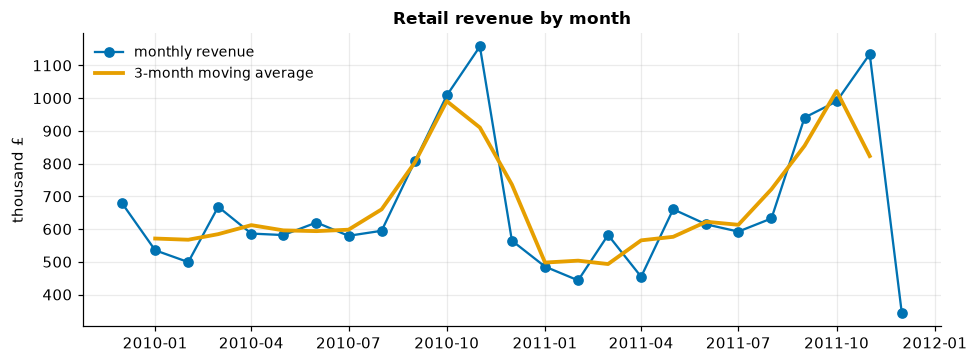

best month: November 2010 with £1,157,765


In [13]:
monthly = sales.set_index("invoice_date")["revenue"].resample("MS").sum()
rolling = monthly.rolling(3, center=True).mean()                   # a 3-month moving average to smooth the noise

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(monthly.index, monthly / 1e3, marker="o", color=style.BLUE, label="monthly revenue")
ax.plot(rolling.index, rolling / 1e3, color=style.ORANGE, lw=2.5, label="3-month moving average")
ax.set(title="Retail revenue by month", ylabel="thousand £"); ax.legend(); plt.tight_layout(); plt.show()
print(f"best month: {monthly.idxmax().strftime('%B %Y')} with £{monthly.max():,.0f}")

In [14]:
# concat stacks tables (same columns) vertically; keys= remembers where each piece came from
y2010, y2011 = sales[sales["invoice_date"].dt.year == 2010], sales[sales["invoice_date"].dt.year == 2011]
stacked = pd.concat({"2010": y2010, "2011": y2011}, names=["year"])
print(f"stacked rows: {len(stacked):,} = {len(y2010):,} + {len(y2011):,};  per-year revenue:")
(stacked.groupby(level="year")["revenue"].sum() / 1e6).round(2).to_frame("£ million")

stacked rows: 756,575 = 386,764 + 369,811;  per-year revenue:


,£ million
year,
2010,8.20
2011,7.87


(The 2011 figure covers fewer months than 2010 because the data ends in early December 2011 and starts in December 2009. Always check *the coverage* of a time period before comparing totals.)

## Pitfalls at a glance

| Surprise | Cause | Fix |
|---|---|---|
| Top-rated items are all obscure | small groups give extreme averages | minimum count, or shrink towards the overall mean |
| Merge result has far more rows | a non-unique key on both sides | make a key unique first; use `validate=` |
| Rows vanished after a merge | default `how="inner"` | `how="left"` and check `indicator=True` |
| Group summary will not line up with rows | used `agg` where you needed `transform` | `transform` for row-aligned results |
| Totals double-count after `explode` | an item now occupies several rows | count distinct ids, not rows |

## Check yourself

<details class="question">
<summary>1. What is the difference between <code>groupby(...).agg(...)</code> and <code>groupby(...).transform(...)</code>?</summary>

`agg` collapses each group to a single row (the result has one row per group). `transform` returns a value for *every original row* (the same length as the input), so you can add it back as a new column, for example "each line's share of its customer's total".

</details>

<details class="question">
<summary>2. A left merge of 1,000 orders with a customer table returns 1,300 rows. What went wrong, and how would <code>validate</code> have helped?</summary>

The customer table has duplicate keys (some customers appear more than once), so each matching order is repeated for every duplicate. `validate="many_to_one"` would have raised an error at the merge, telling you the right-hand key was not unique, instead of letting the extra rows flow into every later calculation.

</details>

<details class="question">
<summary>3. Why does a movie with one 5-star rating top the naive ranking, and what does shrinkage do about it?</summary>

An average of one number has no uncertainty protection, so it can be extreme. Shrinkage blends a movie's own average with the overall average, weighted by how many ratings it has: few ratings means mostly the global mean, many ratings means mostly its own. Extremes now need *evidence* to survive.

</details>

## Exercises

<details class="question">
<summary>Among genres with at least 1,000 ratings, which has the highest average rating, and which the lowest? Why is the 1,000 threshold needed?</summary>

```python
big = genre_stats[genre_stats["n_ratings"] >= 1000].sort_values("mean_rating")
print(big.head(1).round(2)); print(big.tail(1).round(2))
```

War comes out highest (about 3.81) and Horror lowest (about 3.26). The threshold is the small-sample trap again: a genre with a handful of ratings could top the list by luck. Note also that a movie in several genres contributes to each of them, so the genres are not independent groups.

</details>

<details class="question">
<summary>What is the median number of days between a customer's first and last order, and what share of customers have a gap of zero days?</summary>

```python
print(customers["active_days"].median(), f"{(customers['active_days'] == 0).mean():.1%}")
```

The median is about 221 days, and roughly 29% of customers have a gap of zero. A gap of zero means every order fell on a single day: these are essentially one-visit customers. Because `active_days` comes from `max` minus `min` of timestamps, it is only a lower bound for customers who were still active when the data ended.

</details>

## Recap

- `groupby` = split, apply, combine. Use **named aggregation**; use `transform` when the result must align with the rows.
- **Small groups give extreme averages**: use a minimum count or shrink towards the overall mean.
- `merge`: choose `on` and `how` deliberately, **`validate=` the expected cardinality**, and use `indicator=True` to see what matched. A non-unique key on both sides multiplies rows.
- `pivot_table` for two-key summaries, `explode` for list-valued columns (then count carefully), `resample` for time buckets, `concat` to stack.
- Check **coverage** (which dates, which groups) before comparing totals.

**Next:** plotting, to see the patterns these summaries describe.